In [3]:
!pip install -q -U transformers accelerate opencv-python
from huggingface_hub import notebook_login
notebook_login()

config.json:   0%|          | 0.00/25.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/1.71k [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/799 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.64M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/588 [00:00<?, ?B/s]

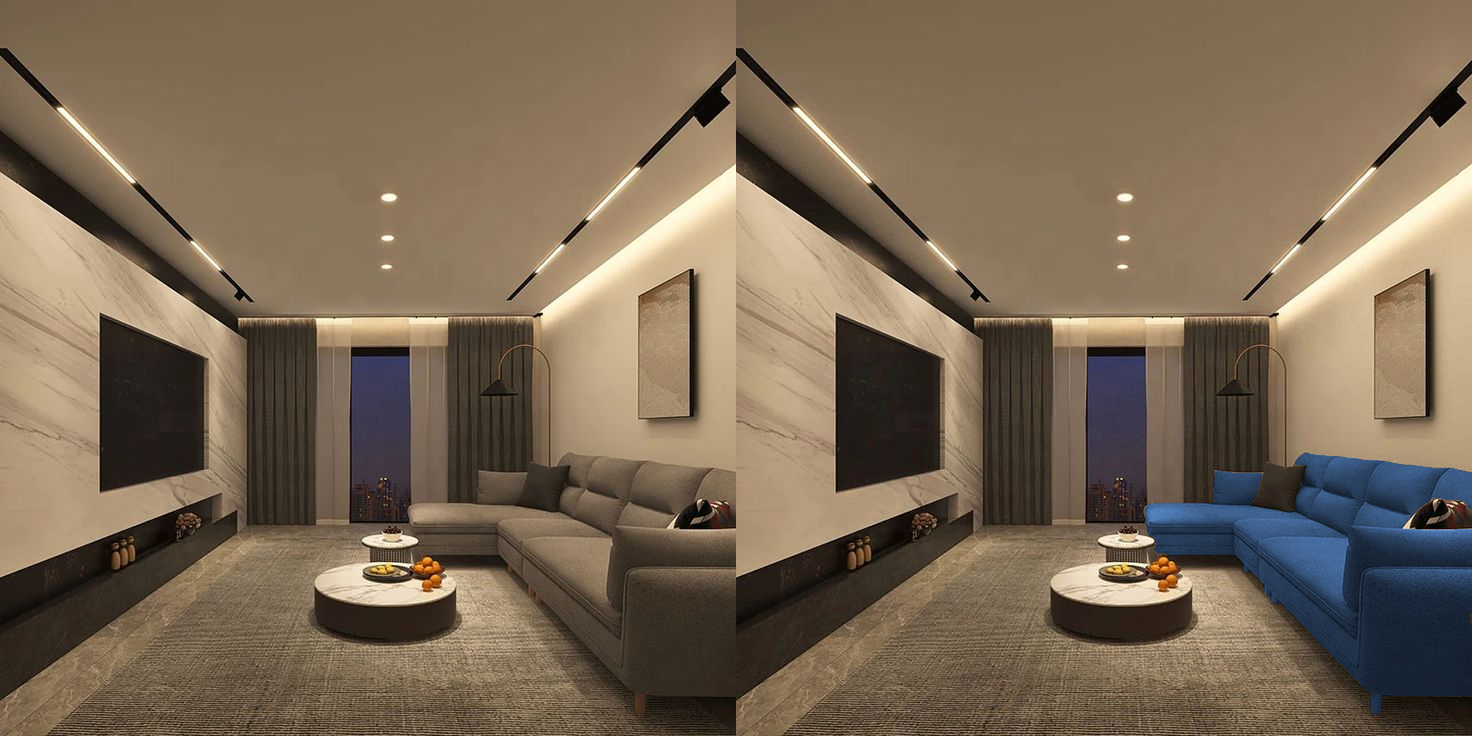

In [4]:
import torch, cv2, numpy as np
from PIL import Image
from transformers import Sam3Model, Sam3Processor

image = Image.open("/content/download.jpg").convert("RGB")
prompt = "sofa"
target_rgb = (70, 110, 160)

model = Sam3Model.from_pretrained("facebook/sam3", device_map="auto")
processor = Sam3Processor.from_pretrained("facebook/sam3")

inputs = processor(images=image, text=prompt, return_tensors="pt").to(model.device)
with torch.no_grad():
    outputs = model(**inputs)

results = processor.post_process_instance_segmentation(
    outputs, threshold=0.5, mask_threshold=0.5,
    target_sizes=inputs.get("original_sizes").tolist()
)[0]

masks = results["masks"].cpu().numpy().astype(bool)
mask = masks.any(axis=0)

img = np.array(image)
hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
tgt = cv2.cvtColor(np.uint8([[target_rgb]]), cv2.COLOR_RGB2HSV)[0, 0]
hsv[mask, 0] = tgt[0]
hsv[mask, 1] = tgt[1]
out = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

Image.fromarray(np.hstack([img, out]))

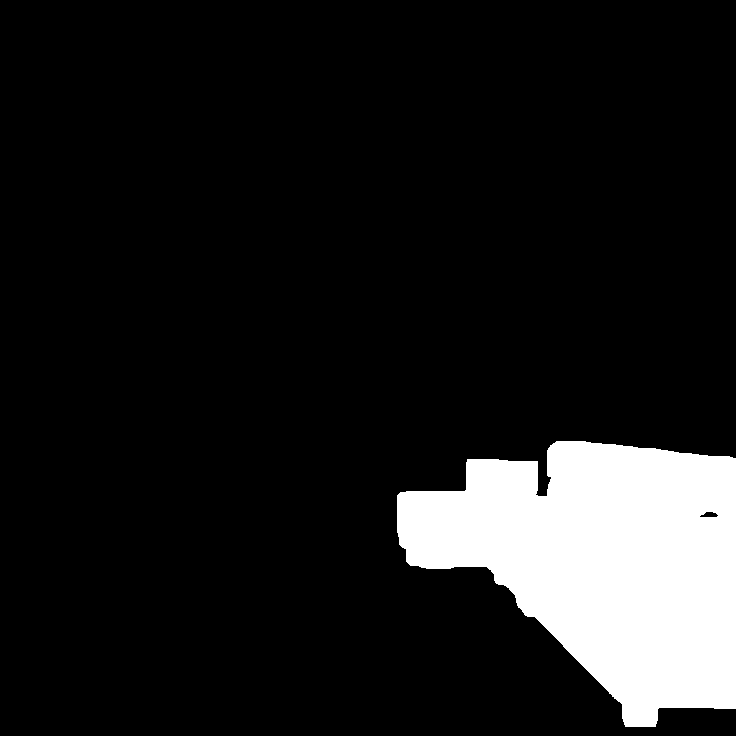

In [5]:
del model, outputs
torch.cuda.empty_cache()
mask = cv2.dilate(mask.astype(np.uint8) * 255, np.ones((25, 25), np.uint8))
Image.fromarray(mask)

In [6]:
!pip install -q -U diffusers

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/690 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


  0%|          | 0/29 [00:00<?, ?it/s]

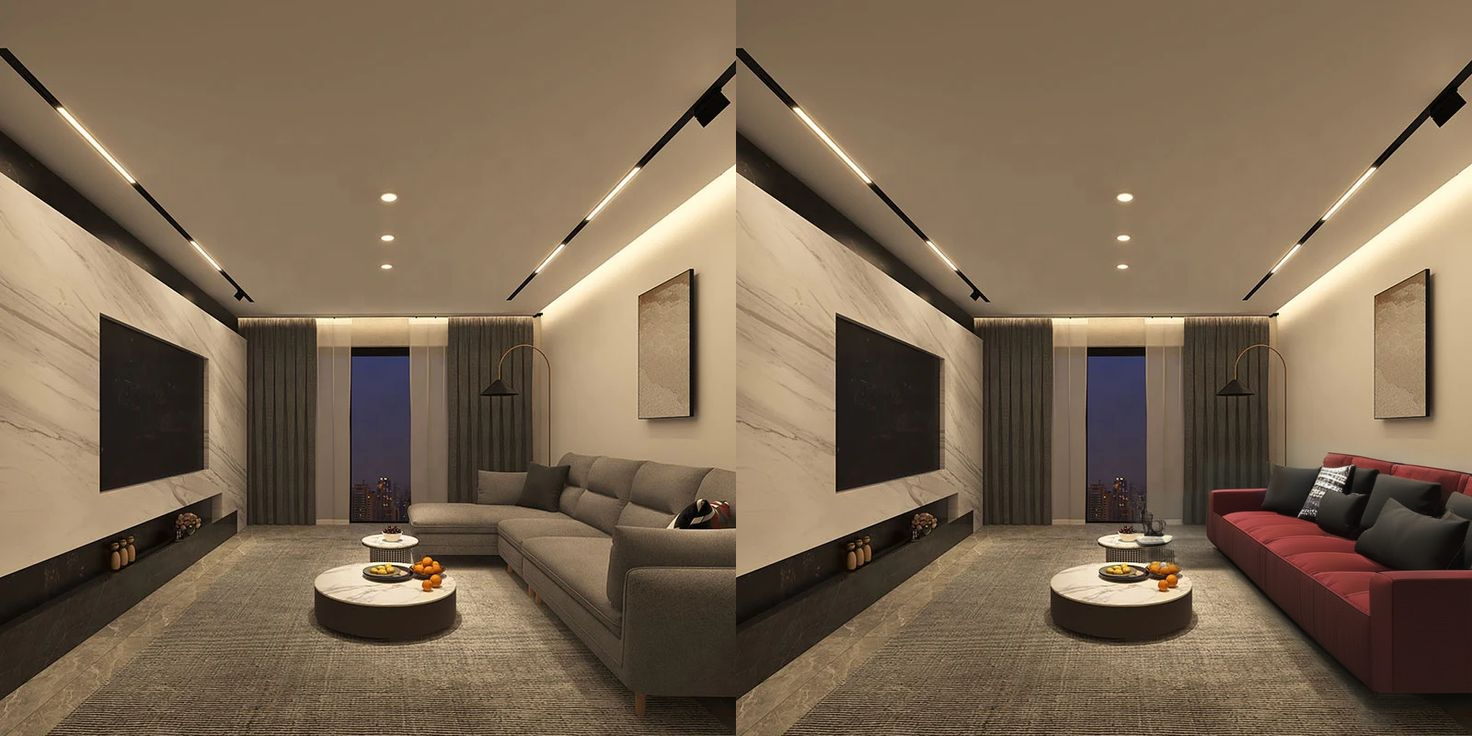

In [7]:
from diffusers import AutoPipelineForInpainting
from PIL import ImageFilter

pipe = AutoPipelineForInpainting.from_pretrained(
    "diffusers/stable-diffusion-xl-1.0-inpainting-0.1",
    torch_dtype=torch.float16, variant="fp16"
)
pipe.enable_model_cpu_offload()

w, h = image.size
s = 1024 / max(w, h)
W, H = int(w * s) // 8 * 8, int(h * s) // 8 * 8

result = pipe(
    prompt="a dark red sofa, modern living room, natural light, photorealistic",
    negative_prompt="blurry, distorted, extra furniture, low quality",
    image=image.resize((W, H)),
    mask_image=Image.fromarray(mask).resize((W, H)),
    strength=0.99, guidance_scale=8, num_inference_steps=30,
    height=H, width=W,
).images[0].resize((w, h))

m = Image.fromarray(mask).filter(ImageFilter.GaussianBlur(4))
final = Image.composite(result, image, m)
final.save("edited.png")
Image.fromarray(np.hstack([np.array(image), np.array(final)]))

  0%|          | 0/29 [00:00<?, ?it/s]

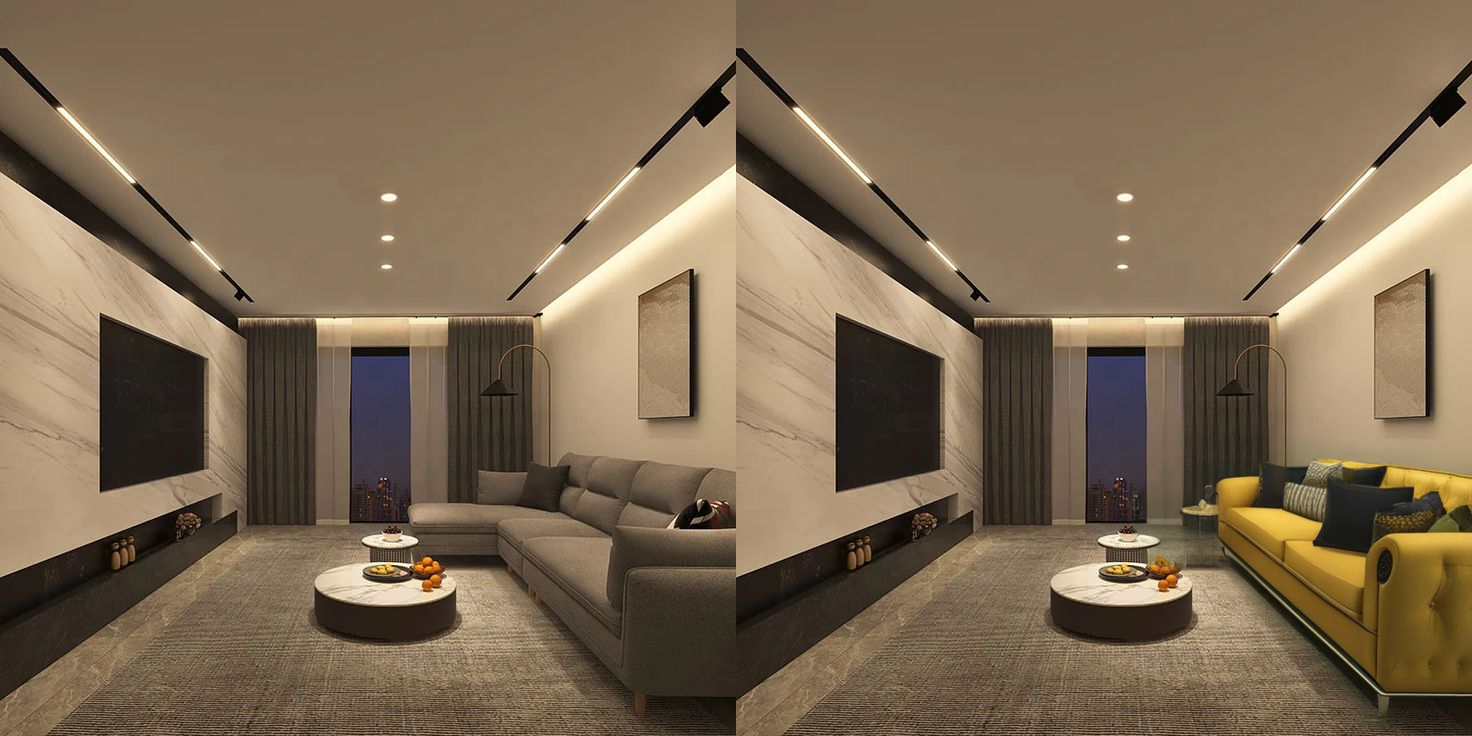

In [9]:
result = pipe(
    prompt="a gold sofa, classic living room, natural light, photorealistic",
    negative_prompt="blurry, distorted, extra furniture, low quality",
    image=image.resize((W, H)),
    mask_image=Image.fromarray(mask).resize((W, H)),
    strength=0.99, guidance_scale=8, num_inference_steps=30,
    height=H, width=W,
).images[0].resize((w, h))

m2 = Image.fromarray(mask).filter(ImageFilter.GaussianBlur(4))
second_final = Image.composite(result, image, m2)
second_final.save("2nd_edited.png")
Image.fromarray(np.hstack([np.array(image), np.array(second_final)]))